## Line chart with styles

In [6]:
import pandas as pd
import sqlite3

conn = sqlite3.connect("../data/checking-logs.sqlite")
schema = pd.read_sql("PRAGMA table_info(checker);", conn)
schema

,cid,name,type,notnull,dflt_value,pk
0,0,index,INTEGER,0,None,0
1,1,status,TEXT,0,None,0
2,2,success,INTEGER,0,None,0
3,3,timestamp,TIMESTAMP,0,None,0
4,4,numTrials,INTEGER,0,None,0
5,5,labname,TEXT,0,None,0
6,6,uid,TEXT,0,None,0


## query for views

In [7]:
query_views = """
    SELECT
        datetime as date
    FROM
        pageviews
    WHERE
        uid LIKE 'user_%'
"""
df_views = pd.read_sql(query_views, conn, parse_dates=['date'])
daily_views = df_views['date'].dt.date.value_counts().sort_index()
daily_views.name = 'views'
daily_views

date
2020-04-17      1
2020-04-18     23
2020-04-19     15
2020-04-21      3
2020-04-22      1
2020-04-23      5
2020-04-25      1
2020-04-26      8
2020-04-28      2
2020-04-29      4
2020-04-30      9
2020-05-01      3
2020-05-02      6
2020-05-03     19
2020-05-04      1
2020-05-05      1
2020-05-06      3
2020-05-07      2
2020-05-08     48
2020-05-09     19
2020-05-10    110
2020-05-11    200
2020-05-12     85
2020-05-13    102
2020-05-14    187
2020-05-15     29
2020-05-16      4
2020-05-17      9
2020-05-18     51
2020-05-19     11
2020-05-20     12
2020-05-21     11
2020-05-22      2
Name: views, dtype: int64

## query for commits

In [8]:
query_commits = """
    SELECT
        timestamp as date
    FROM
        checker
    WHERE
        uid LIKE 'user_%' AND status = 'ready'
"""
df_commits = pd.read_sql(query_commits, conn, parse_dates=['date'])
daily_commits = df_commits['date'].dt.date.value_counts().sort_index()
daily_commits.name = 'commits'
daily_commits.info()

<class 'pandas.core.series.Series'>
Index: 35 entries, 2020-04-17 to 2020-05-21
Series name: commits
Non-Null Count  Dtype
--------------  -----
35 non-null     int64
dtypes: int64(1)
memory usage: 560.0+ bytes


## merge and make a plot for df

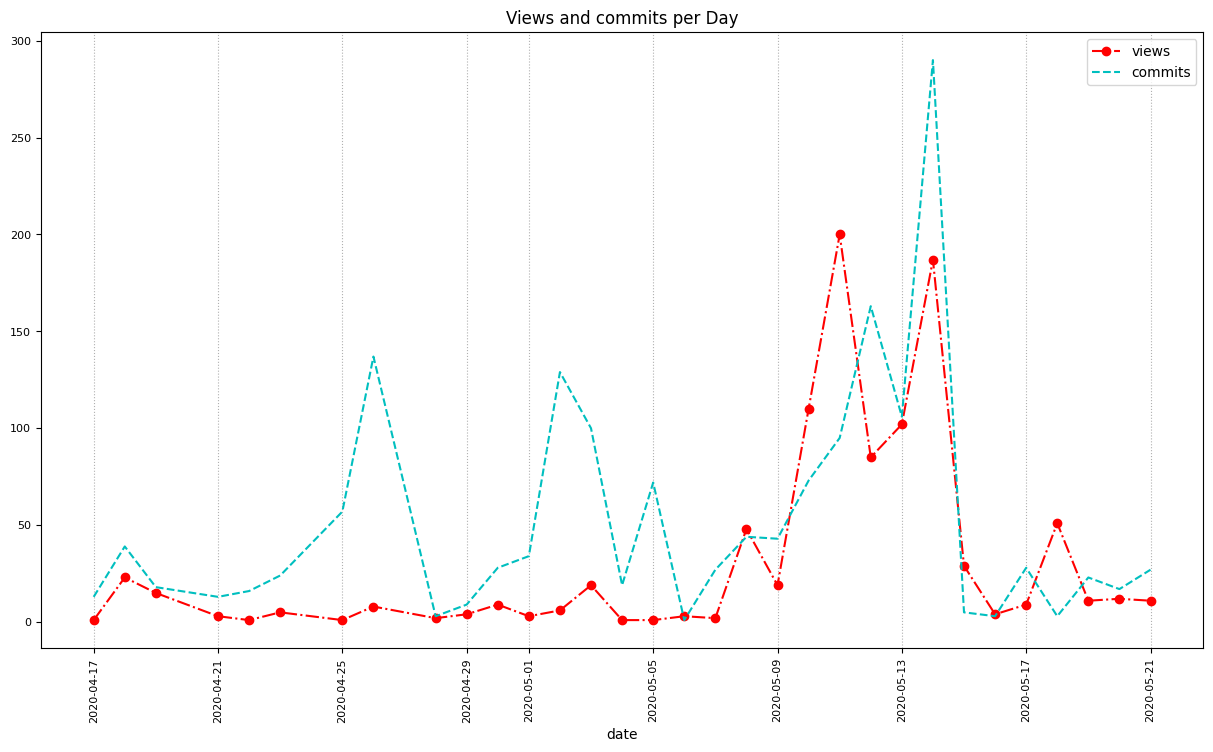

In [9]:
merged_data = pd.concat([daily_views, daily_commits], axis=1, join='inner')
plot = merged_data.plot(
    figsize=(15, 8),
    fontsize=8,
    rot=90,
    title='Views and commits per Day',
    style=['r-.o', 'c--'],
)
plot.grid(True, axis='x', linestyle=':')
conn.close()

In [11]:
merged_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 32 entries, 2020-04-17 to 2020-05-21
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   views    32 non-null     int64
 1   commits  32 non-null     int64
dtypes: int64(2)
memory usage: 1.8+ KB


## How many times was the number of views larger than 150?

In [10]:
views_over_150 = (merged_data['views'] > 150).sum()
print(f"The answer is {views_over_150}.")

The answer is 2.
